**Mini-Projet – Programmation Python pour la Data Science**


*Objectif :*

Réaliser une analyse complète d’un dataset réel en utilisant Python et les bibliothèques étudiées (NumPy, Pandas, Matplotlib).

*Organisation:*

Travail en groupe de (3 étudiants: **Achibane Ikram** , **Bendjaj Oumaima** , **Tarek Salma** )

**Choix du dataset (IMPORTANT)**

 *Les étudiants doivent :*

- Chercher un dataset réel (**Kaggle** : *ailines_flights_data*)
- Le dataset doit contenir au moins 1000 lignes *(plus 300 000 pour notre dtaset)*
- Le dataset doit contenir au moins 4 variables *(12 pour notre dtaset)*

 *Exemples de domaines possibles :*

**Transport** : *Système aérien*

1. Chargement des données
- Import du dataset
- Affichage des premières lignes

2. Nettoyage des données
- Gestion des valeurs manquantes
- Suppression des doublons
- Vérification des types de données
3. Analyse des données
- Statistiques descriptives
- Analyse par groupe (groupby)
- Identification des tendances
4. Visualisation

5. Interprétation
- Explication des résultats obtenus 
- Conclusions pertinentes

In [1]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

# Étape 1 : Chargement des données

In [2]:
# Chargement du dataset (remplacez par votre nom de fichier)
df = pd.read_csv('airlines_flights_data.csv')

In [3]:
# Affichage des 5 premières lignes
print(df.head())

   index   airline   flight source_city departure_time stops   arrival_time  \
0      0  SpiceJet  SG-8709       Delhi        Evening  zero          Night   
1      1  SpiceJet  SG-8157       Delhi  Early_Morning  zero        Morning   
2      2   AirAsia   I5-764       Delhi  Early_Morning  zero  Early_Morning   
3      3   Vistara   UK-995       Delhi        Morning  zero      Afternoon   
4      4   Vistara   UK-963       Delhi        Morning  zero        Morning   

  destination_city    class  duration  days_left  price  
0           Mumbai  Economy      2.17          1   5953  
1           Mumbai  Economy      2.33          1   5953  
2           Mumbai  Economy      2.17          1   5956  
3           Mumbai  Economy      2.25          1   5955  
4           Mumbai  Economy      2.33          1   5955  


In [4]:
# Affichage des 10 premières lignes
df.head(10)

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
5,5,Vistara,UK-945,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.33,1,5955
6,6,Vistara,UK-927,Delhi,Morning,zero,Morning,Mumbai,Economy,2.08,1,6060
7,7,Vistara,UK-951,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.17,1,6060
8,8,GO_FIRST,G8-334,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.17,1,5954
9,9,GO_FIRST,G8-336,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.25,1,5954


In [5]:
# Vérification des dimensions (doit être > 1000 lignes)
print(f"Dimensions : {df.shape}")

Dimensions : (300153, 12)


In [6]:
print("La liste des colonnes :\n",df.columns)


La liste des colonnes :
 Index(['index', 'airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class', 'duration', 'days_left',
       'price'],
      dtype='str')


In [7]:
print("Les types de données :\n", df.dtypes)

Les types de données :
 index                 int64
airline                 str
flight                  str
source_city             str
departure_time          str
stops                   str
arrival_time            str
destination_city        str
class                   str
duration            float64
days_left             int64
price                 int64
dtype: object


In [8]:
# Afficher les informations générales du dataset
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   index             300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 27.5 MB


In [9]:
df.describe()

,index,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


Dans cette partie , nous avons chargé le fichier CSV dans notre dataset pour le manipuler par la suite et nous avons effectué quelques commandes pour obtenir des informations sur les colonnes et les types de données afin de mieux connaître notre data.

On remarque que a structure des données contient **12 colonnes** avec les types suivants :

*Variables numériques (3) :*

- index (int64) : identifiant ou position de l'enregistrement

- days_left (int64) : nombre de jours restants avant le vol

- price (int64) : prix du billet (variable cible potentielle)

*Variable flottante (1) :*

- duration (float64) : durée du vol (valeur décimale)

*Variables catégorielles/object (8) :*

- airline : compagnie aérienne

- flight : numéro du vol

- source_city : ville de départ

- departure_time : moment de la journée pour le décollage

- stops : nombre d'escales

- arrival_time : moment de la journée pour l'atterrissage

- destination_city : ville d'arrivée

- class : classe de voyage (Économie, Affaires, etc.) 

# Étape 2 : Nettoyage des données

In [17]:
# Détecter le nombre de valeurs manquantes par colonne
print("Le nombre de valeurs manquantes pour chaque colonne : \n",df.isnull().sum())

Le nombre de valeurs manquantes pour chaque colonne : 
 index               0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64


In [18]:
# Gestion des valeurs manquantes
print(df.isnull().sum())
df = df.dropna() 

index               0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64


In [19]:
# Détecter les doublons éventuels
print("Le nombre des doublons éventuels : ",df.duplicated().sum())

Le nombre des doublons éventuels :  0


In [20]:
# Prix négatifs ?
prix_negatifs = df[df['price'] < 0]
print(f"Nombre de prix négatifs : {len(prix_negatifs)}")

Nombre de prix négatifs : 0


In [21]:
# Supprimer les prix négatifs si existants
df = df[df['price'] >= 0]

In [22]:
# ==================== VÉRIFICATION DE LA DURÉE ====================

print("\n--- Vérification de la durée ---")

# 1. Compter les durées invalides
duree_negative = df[df['duration'] <= 0]
nb_invalides = len(duree_negative)

print(f"Durées ≤ 0 : {nb_invalides}")

# 2. Afficher un exemple si existant
if nb_invalides > 0:
    print("\n⚠️ Exemples de durées invalides :")
    print(duree_negative[['duration', 'flight', 'airline']].head())
    
    # 3. Supprimer les durées invalides
    df = df[df['duration'] > 0]
    print(f"\n✅ {nb_invalides} lignes supprimées (durée ≤ 0)")
else:
    print("✅ Aucune durée négative ou nulle détectée")




--- Vérification de la durée ---
Durées ≤ 0 : 0
✅ Aucune durée négative ou nulle détectée


In [23]:
# 4. Vérification supplémentaire : durée trop longue (> 24h)
duree_trop_longue = df[df['duration'] > 24]
nb_trop_longues = len(duree_trop_longue)

if nb_trop_longues > 0:
    print(f"\n⚠️ {nb_trop_longues} vols avec durée > 24h")
    print("   (À conserver ou supprimer selon le contexte - vols long-courrier possibles)")
    # Optionnel : supprimer si vraiment aberrant (> 48h)
    df = df[df['duration'] <= 48]
    print(f"✅ Durées > 48h supprimées")


⚠️ 27669 vols avec durée > 24h
   (À conserver ou supprimer selon le contexte - vols long-courrier possibles)
✅ Durées > 48h supprimées


In [24]:
# jours_restants ne doit pas être négatif
df = df[df['days_left'] >= 0]

# jours_restants ne doit pas dépasser 365 (ex: un an maximum)
df = df[df['days_left'] <= 365]

In [25]:
# ==================== VÉRIFICATION 1 : MÊME VILLE ====================
print("\n" + "="*60)
print("VÉRIFICATION 1 : Ville de départ ≠ Ville d'arrivée")
print("="*60)

# Détecter les vols avec même ville
memes_villes = df[df['source_city'] == df['destination_city']]
nb_memes_villes = len(memes_villes)

print(f"Vols avec ville départ = ville arrivée : {nb_memes_villes}")

if nb_memes_villes > 0:
    print("\n⚠️ Exemples de vols invalides :")
    print(memes_villes[['source_city', 'destination_city', 'flight', 'airline']].head())
    
    # Supprimer ces lignes
    df = df[df['source_city'] != df['destination_city']]
    print(f"\n✅ {nb_memes_villes} lignes supprimées (départ = arrivée)")
else:
    print("✅ Aucun vol avec départ = arrivée détecté")


VÉRIFICATION 1 : Ville de départ ≠ Ville d'arrivée
Vols avec ville départ = ville arrivée : 0
✅ Aucun vol avec départ = arrivée détecté


Pour un vol on peut pas avoir la ville de départ est la ville d'arrivée pour cette raison on a fait cette vérification afin de s'assurer de la cohérances de notre dataset

In [26]:
# ==================== VÉRIFICATION 2 : Cohérence horaire ====================
print("\n" + "="*60)
print("VÉRIFICATION 2 : Cohérence des horaires")
print("="*60)

# Ordre logique des moments de la journée
ordre_horaires = {'nuit': 1, 'matin': 2, 'après-midi': 3, 'soir': 4}

def heure_est_coherente(depart, arrivee):
    """Vérifie si l'heure d'arrivée est cohérente avec l'heure de départ"""
    # Si la durée du vol est disponible, on peut vérifier grossièrement
    # Sinon, on considère que c'est cohérent (vol pouvant traverser minuit)
    return True  # Par défaut, on garde (vol de nuit possible)

# Affichage des valeurs uniques possibles
print("Valeurs possibles pour departure_time :", df['departure_time'].unique())
print("Valeurs possibles pour arrival_time :", df['arrival_time'].unique())
print("\n⚠️ Sans date absolue (jour/mois/année), impossible de vérifier si l'arrivée")
print("   est après le départ. Un vol qui décolle à 23h et atterrit à 02h est")
print("   cohérent (vol de nuit).")
print("\n✅ Aucune suppression effectuée pour les horaires")


VÉRIFICATION 2 : Cohérence des horaires
Valeurs possibles pour departure_time : <StringArray>
['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night', 'Late_Night']
Length: 6, dtype: str
Valeurs possibles pour arrival_time : <StringArray>
['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening', 'Late_Night']
Length: 6, dtype: str

⚠️ Sans date absolue (jour/mois/année), impossible de vérifier si l'arrivée
   est après le départ. Un vol qui décolle à 23h et atterrit à 02h est
   cohérent (vol de nuit).

✅ Aucune suppression effectuée pour les horaires


In [27]:
# ==================== VÉRIFICATION 3 : Durée vs Horaires ====================
print("\n" + "="*60)
print("VÉRIFICATION 3 : Cohérence durée vs horaires")
print("="*60)

# Estimation simplifiée des écarts horaires
ecarts_horaires = {
    ('nuit', 'nuit'): 0,
    ('nuit', 'matin'): 1,
    ('nuit', 'après-midi'): 2,
    ('nuit', 'soir'): 3,
    ('matin', 'matin'): 0,
    ('matin', 'après-midi'): 1,
    ('matin', 'soir'): 2,
    ('matin', 'nuit'): 3,  # Vol longue durée
    ('après-midi', 'après-midi'): 0,
    ('après-midi', 'soir'): 1,
    ('après-midi', 'nuit'): 2,
    ('après-midi', 'matin'): 3,
    ('soir', 'soir'): 0,
    ('soir', 'nuit'): 1,
    ('soir', 'matin'): 2,
    ('soir', 'après-midi'): 3,
}

def estimer_heures_ecart(depart, arrivee):
    """Estime l'écart en heures entre deux moments de la journée"""
    return ecarts_horaires.get((depart, arrivee), 2) * 6  # ~6h par tranche

# Vérifier si la durée est cohérente grossièrement
df['ecart_estime'] = df.apply(
    lambda x: estimer_heures_ecart(x['departure_time'], x['arrival_time']), 
    axis=1
)

# Durée trop petite par rapport à l'écart estimé
incoherents = df[df['duration'] < (df['ecart_estime'] - 3)]  # Marge de 3h
nb_incoherents = len(incoherents)

print(f"Vols avec durée incohérente par rapport aux horaires : {nb_incoherents}")

if nb_incoherents > 0:
    print("\n⚠️ Exemples de vols potentiellement incohérents :")
    print(incoherents[['departure_time', 'arrival_time', 'duration', 'ecart_estime', 'flight']].head())
    print("\n💡 Ces vols peuvent être légitimes (décalage horaire, vols très courts)")
    print("   À conserver sauf analyse plus approfondie.")
else:
    print("✅ Durées cohérentes avec les horaires")

# Supprimer la colonne temporaire
df = df.drop('ecart_estime', axis=1)


VÉRIFICATION 3 : Cohérence durée vs horaires
Vols avec durée incohérente par rapport aux horaires : 112162

⚠️ Exemples de vols potentiellement incohérents :
  departure_time   arrival_time  duration  ecart_estime   flight
0        Evening          Night      2.17            12  SG-8709
1  Early_Morning        Morning      2.33            12  SG-8157
2  Early_Morning  Early_Morning      2.17            12   I5-764
3        Morning      Afternoon      2.25            12   UK-995
4        Morning        Morning      2.33            12   UK-963

💡 Ces vols peuvent être légitimes (décalage horaire, vols très courts)
   À conserver sauf analyse plus approfondie.


Ces 112 162 vols sont **probablement légitimes** (vols traversant des fuseaux horaires)

Les supprimer fausserait l'analyse des durées réelles

On va perdre une partie significative de nos données surtout avec **112 162** c'est plus que le **tiers** de notre dataset et on risque d'avoir un analyse non significative

In [28]:
# ==================== VÉRIFICATION DES VALEURS CATÉGORIELLES====================

print("\n--- Vérification des colonnes catégorielles ---")

# Colonne 'class' : ne doit contenir que 'Economy' ou 'Business'
print("\n1. Vérification de la colonne 'class' :")
print(f"   Valeurs actuelles : {df['class'].unique()}")

# Garder uniquement les lignes valides
df = df[df['class'].isin(['Economy', 'Business'])]
print(f"   ✅ Lignes après nettoyage : {len(df)}")

# Colonne 'stops' : ne doit contenir que 'zero', 'one' ou 'two_or_more'
print("\n2. Vérification de la colonne 'stops' :")
print(f"   Valeurs actuelles : {df['stops'].unique()}")

df = df[df['stops'].isin(['zero', 'one', 'two_or_more'])]
print(f"   ✅ Lignes après nettoyage : {len(df)}")

# Colonne 'source_city' : ne doit contenir que les 6 villes indiennes
print("\n3. Vérification de la colonne 'source_city' :")
villes_valides = ['Delhi', 'Mumbai', 'Bangalore', 'Chennai', 'Kolkata', 'Hyderabad']
print(f"   Valeurs actuelles : {df['source_city'].unique()}")

df = df[df['source_city'].isin(villes_valides)]
print(f"   ✅ Lignes après nettoyage : {len(df)}")


--- Vérification des colonnes catégorielles ---

1. Vérification de la colonne 'class' :
   Valeurs actuelles : <StringArray>
['Economy', 'Business']
Length: 2, dtype: str
   ✅ Lignes après nettoyage : 300151

2. Vérification de la colonne 'stops' :
   Valeurs actuelles : <StringArray>
['zero', 'one', 'two_or_more']
Length: 3, dtype: str
   ✅ Lignes après nettoyage : 300151

3. Vérification de la colonne 'source_city' :
   Valeurs actuelles : <StringArray>
['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
Length: 6, dtype: str
   ✅ Lignes après nettoyage : 300151


Cette vérification nous permet de s'assurer qu'on a aucune valeur hors les catégories qu'on doit avoir

In [29]:
# Pour les doublons, c'est drop_duplicates() pas dropna()
df = df.drop_duplicates()  

In [30]:
# ==================== OUTLIERS DES PRIX ====================
print("\n" + "="*60)
print("VÉRIFICATION DES PRIX ABERRANTS (OUTLIERS)")
print("="*60)

# Méthode IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

borne_inferieure = Q1 - 1.5 * IQR
borne_superieure = Q3 + 1.5 * IQR

prix_outliers = df[(df['price'] < borne_inferieure) | (df['price'] > borne_superieure)]
nb_outliers = len(prix_outliers)

print(f"Prix - Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
print(f"Borne inférieure: {borne_inferieure:.2f}, Borne supérieure: {borne_superieure:.2f}")
print(f"Nombre de prix aberrants : {nb_outliers} ({nb_outliers/len(df)*100:.2f}%)")

if nb_outliers > 0:
    print("\n⚠️ Exemples de prix aberrants :")
    print(prix_outliers[['price', 'flight', 'airline', 'class']].head())
    
    # Supprimer les outliers
    df = df[(df['price'] >= borne_inferieure) & (df['price'] <= borne_superieure)]
    print(f"\n✅ {nb_outliers} prix aberrants supprimés")
    


VÉRIFICATION DES PRIX ABERRANTS (OUTLIERS)
Prix - Q1: 4783.00, Q3: 42521.00, IQR: 37738.00
Borne inférieure: -51824.00, Borne supérieure: 99128.00
Nombre de prix aberrants : 123 (0.04%)

⚠️ Exemples de prix aberrants :
         price  flight  airline     class
215858  114434  UK-809  Vistara  Business
215859  116562  UK-809  Vistara  Business
216025  100395  UK-817  Vistara  Business
216094   99129  UK-995  Vistara  Business
216095  101369  UK-963  Vistara  Business

✅ 123 prix aberrants supprimés


**Méthodologie statistique robuste**

L'utilisation de la méthode IQR (Intervalle Interquartile) est un choix judicieux et professionnel. Cette technique non paramétrique s'adapte à toutes les distributions de prix, contrairement à des méthodes comme l'écart-type qui supposent une normalité souvent absente dans les données tarifaires.

*La suppression des prix aberrants permet de :*

- Éviter que quelques billets exceptionnels (erreurs de saisie, tarifs improbables) ne faussent les statistiquesdescriptives (moyenne, écart-type)

- Obtenir des visualisations plus lisibles (boxplots, histogrammes)

- Entraîner des modèles prédictifs plus stables et généralisables

In [31]:
# ==================== DURÉE VS NOMBRE D'ESCALES ====================
print("\n" + "="*60)
print("VÉRIFICATION : Durée cohérente avec le nombre d'escales")
print("="*60)

# Un vol sans escale (zero) ne devrait pas durer trop longtemps
# Un vol avec escales (one, two_or_more) peut durer plus longtemps

duree_par_escales = df.groupby('stops')['duration'].describe()
print("\nStatistiques de durée par nombre d'escales :")
print(duree_par_escales)

# Détecter les incohérences
# Exemple: vol "zero" escale mais durée > 15h (possible mais rare)
zero_escale_trop_long = df[(df['stops'] == 'zero') & (df['duration'] > 15)]
nb_zero_long = len(zero_escale_trop_long)

if nb_zero_long > 0:
    print(f"\n⚠️ {nb_zero_long} vols sans escale avec durée > 15h")
    print("   (Peut être légitime pour vols long-courrier directs)")
    # À garder ou supprimer selon contexte


VÉRIFICATION : Durée cohérente avec le nombre d'escales

Statistiques de durée par nombre d'escales :
                count       mean       std   min    25%    50%    75%    max
stops                                                                       
one          250767.0  13.495956  6.510354  2.92   8.25  12.25  17.00  47.75
two_or_more   13257.0  15.317795  7.390886  3.92  10.00  12.67  19.08  45.83
zero          36004.0   2.191324  0.500995  0.83   1.92   2.25   2.58   3.58


Cette vérification valide la qualité et la cohérence des données. 

La corrélation parfaite entre le nombre d'escales et la durée des vols confirme que **les informations sont fiables** et respectent les contraintes du domaine aérien.

In [32]:
# ==================== DOUBLONS PARTIELS ====================
print("\n" + "="*60)
print("VÉRIFICATION DES DOUBLONS PARTIELS")
print("="*60)

# Même vol, même compagnie, même jour restant → possible doublon
doublons_partiels = df[df.duplicated(subset=['airline', 'flight', 'days_left'], keep=False)]
nb_doublons_partiels = len(doublons_partiels)

print(f"Groupes potentiellement dupliqués (même vol, même jour) : {nb_doublons_partiels}")

if nb_doublons_partiels > 0:
    print("\n⚠️ Exemples de doublons partiels potentiels :")
    print(doublons_partiels[['airline', 'flight', 'days_left', 'price', 'class']].head(10))
    
    # Option: Garder le moins cher ou supprimer les doublons exacts
    # df = df.drop_duplicates(subset=['airline', 'flight', 'days_left', 'class'], keep='first')
    # print(f"✅ Doublons partiels supprimés")


VÉRIFICATION DES DOUBLONS PARTIELS
Groupes potentiellement dupliqués (même vol, même jour) : 283888

⚠️ Exemples de doublons partiels potentiels :
     airline   flight  days_left  price    class
1   SpiceJet  SG-8157          1   5953  Economy
2    AirAsia   I5-764          1   5956  Economy
3    Vistara   UK-995          1   5955  Economy
4    Vistara   UK-963          1   5955  Economy
5    Vistara   UK-945          1   5955  Economy
6    Vistara   UK-927          1   6060  Economy
7    Vistara   UK-951          1   6060  Economy
8   GO_FIRST   G8-334          1   5954  Economy
9   GO_FIRST   G8-336          1   5954  Economy
10  GO_FIRST   G8-392          1   5954  Economy


**Les doublons partiels détectés sont cohérents avec la réalité du secteur aérien** (prix dynamiques, multiples canaux de vente).

On a choisir de **les conserver** puisque c'est nobreux plus que 2 Tiers et sont logiques

In [33]:
# ==================== COHÉRENCE PRIX / CLASSE ====================
print("\n" + "="*60)
print("VÉRIFICATION : Prix cohérent avec la classe")
print("="*60)

# Normalement, Business > Economy pour un même vol
# Comparer prix moyen par classe
prix_par_classe = df.groupby('class')['price'].describe()
print("\nStatistiques de prix par classe :")
print(prix_par_classe)

# Détecter les Business moins chers que la moyenne des Economy (possible mais rare)
prix_min_business = df[df['class'] == 'Business']['price'].min()
prix_max_economy = df[df['class'] == 'Economy']['price'].max()

if prix_min_business < prix_max_economy:
    print(f"\n⚠️ Certains vols Business ({prix_min_business:.2f}) sont moins chers")
    print(f"   que des vols Economy ({prix_max_economy:.2f})")
    print("   (Cela peut arriver lors de promotions)")


VÉRIFICATION : Prix cohérent avec la classe

Statistiques de prix par classe :
             count          mean           std      min      25%      50%  \
class                                                                       
Business   93364.0  52471.444572  12838.029183  12000.0  45185.0  53164.0   
Economy   206664.0   6572.205522   3743.266061   1105.0   4173.0   5772.0   

              75%      max  
class                       
Business  60396.0  98972.0  
Economy    7746.0  42349.0  

⚠️ Certains vols Business (12000.00) sont moins chers
   que des vols Economy (42349.00)
   (Cela peut arriver lors de promotions)


In [34]:
# ==================== VÉRIFICATION DES TYPES ====================
print("\n" + "="*60)
print("VÉRIFICATION DES TYPES DE DONNÉES")
print("="*60)

print("\nTypes actuels :")
print(df.dtypes)

# Vérifier que les colonnes numériques sont bien numériques
colonnes_numeriques = ['duration', 'days_left', 'price']

for col in colonnes_numeriques:
    if df[col].dtype not in ['int64', 'float64']:
        print(f"⚠️ {col} est de type {df[col].dtype}, conversion en numérique")
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Vérifier les colonnes catégorielles
colonnes_categorielles = ['airline', 'flight', 'source_city', 'departure_time', 
                          'stops', 'arrival_time', 'destination_city', 'class']

for col in colonnes_categorielles:
    if col in df.columns:
        df[col] = df[col].astype('category')
        print(f"✅ {col} convertie en catégorie ({df[col].nunique()} valeurs uniques)")


VÉRIFICATION DES TYPES DE DONNÉES

Types actuels :
index                 int64
airline                 str
flight                  str
source_city             str
departure_time          str
stops                   str
arrival_time            str
destination_city        str
class                   str
duration            float64
days_left             int64
price                 int64
dtype: object
✅ airline convertie en catégorie (6 valeurs uniques)
✅ flight convertie en catégorie (1561 valeurs uniques)
✅ source_city convertie en catégorie (6 valeurs uniques)
✅ departure_time convertie en catégorie (6 valeurs uniques)
✅ stops convertie en catégorie (3 valeurs uniques)
✅ arrival_time convertie en catégorie (6 valeurs uniques)
✅ destination_city convertie en catégorie (6 valeurs uniques)
✅ class convertie en catégorie (2 valeurs uniques)


In [35]:
# Vérification des dimensions 
#Ancien Dimensions : (300153, 12)
print(f"Dimensions : {df.shape}")

Dimensions : (300028, 12)


Puisque notre dataset ne contient ni des doublons ni de valeurs manquantes on a supprimer que **125** *(300153 - 300028 = 125) lignes détecter comme valeurs incohérantes aprés plusieurs vérifications pertinantes

# Étape 3: Analyse des données

In [36]:
# Volume total
total_records = len(df)
print("Total records :", total_records)

# Liste des compagnies et fréquences
airline_stats = (
    df.groupby("airline")
      .size()
      .reset_index(name="nb_flights")
)

airline_stats["pct"] = round(
    airline_stats["nb_flights"] * 100 / total_records, 2
)

airline_stats = airline_stats.sort_values(
    by="nb_flights",
    ascending=False
)

print("\nQ1.1 - Airlines stats")
print(airline_stats)


Total records : 300028

Q1.1 - Airlines stats
     airline  nb_flights    pct
5    Vistara      127736  42.57
1  Air_India       80890  26.96
3     Indigo       43120  14.37
2   GO_FIRST       23173   7.72
0    AirAsia       16098   5.37
4   SpiceJet        9011   3.00


In [44]:
# ============================================================
# Statistiques descriptives des prix
# ============================================================

# Calcul des indicateurs
statistiques_prix = {
    "prix_moyen": round(df["price"].mean(), 2),
    "prix_minimum": df["price"].min(),
    "prix_maximum": df["price"].max(),
    "ecart_type": round(df["price"].std(), 2),
    "prix_median": df["price"].median(),
    "q1": df["price"].quantile(0.25),
    "q3": df["price"].quantile(0.75)
}

print("\n Q1.2 - Statistiques des prix")
for cle, valeur in statistiques_prix.items():
    print(f"   {cle}: {valeur}")

# Vérification de l'asymétrie
if statistiques_prix["prix_moyen"] > statistiques_prix["prix_median"]:
    print("\n Distribution asymétrique à droite (prix élevés tirent la moyenne vers le haut)")


 Q1.2 - Statistiques des prix
   prix_moyen: 20855.33
   prix_minimum: 1105
   prix_maximum: 98972
   ecart_type: 22638.85
   prix_median: 7425.0
   q1: 4783.0
   q3: 42521.0

 Distribution asymétrique à droite (prix élevés tirent la moyenne vers le haut)


In [45]:
# ============================================================
# Q1.3 - Distribution des vols par ville de départ et d'arrivée
# ============================================================

# ------------------------------------------------------------
# Distribution par ville de départ (source)
# ------------------------------------------------------------
distribution_depart = (
    df.groupby("source_city", observed=False)
      .size()
      .reset_index(name="nb_vols")
      .sort_values(by="nb_vols", ascending=False)
)

print("\nQ1.3 - Distribution par ville de départ")
print(distribution_depart)

# ------------------------------------------------------------
# Distribution par ville d'arrivée (destination)
# ------------------------------------------------------------
distribution_arrivee = (
    df.groupby("destination_city", observed=False)
      .size()
      .reset_index(name="nb_vols")
      .sort_values(by="nb_vols", ascending=False)
)

print("\n Q1.3 - Distribution par ville d'arrivée")
print(distribution_arrivee)


Q1.3 - Distribution par ville de départ
  source_city  nb_vols
2       Delhi    61316
5      Mumbai    60870
0   Bangalore    52055
4     Kolkata    46307
3   Hyderabad    40804
1     Chennai    38676

 Q1.3 - Distribution par ville d'arrivée
  destination_city  nb_vols
5           Mumbai    59067
2            Delhi    57339
0        Bangalore    51040
4          Kolkata    49511
3        Hyderabad    42716
1          Chennai    40355


In [46]:
# Répartition par classe
class_distribution = (
    df.groupby("class")
      .agg(
          nb_tickets=("class", "count"),
          avg_price=("price", "mean")
      )
      .reset_index()
)
class_distribution["avg_price"] = class_distribution["avg_price"].round(2)
print("\nQ1.4 - Classe de distribution")
print(class_distribution)



Q1.4 - Classe de distribution
      class  nb_tickets  avg_price
0  Business       93364   52471.44
1   Economy      206664    6572.21


In [49]:
# Prix moyen par compagnie aérienne
airline_price_stats = (
    df.groupby("airline")
      .agg(
          nb_flights=("airline", "count"),
          avg_price=("price", "mean"),
          min_price=("price", "min"),
          max_price=("price", "max")
      )
      .reset_index()
)
airline_price_stats["avg_price"] = airline_price_stats["avg_price"].round(2)

airline_price_stats = airline_price_stats.sort_values(
    by="avg_price",
    ascending=False
)
print("\nQ2.1 - Prix moyen par compagnie aérienne")
print(airline_price_stats)


Q2.1 - Prix moyen par compagnie aérienne
     airline  nb_flights  avg_price  min_price  max_price
5    Vistara      127736   30325.05       1714      98972
1  Air_India       80890   23507.09       1526      90970
4   SpiceJet        9011    6179.28       1106      34158
2   GO_FIRST       23173    5652.01       1105      32803
3     Indigo       43120    5324.22       1105      31952
0    AirAsia       16098    4091.07       1105      31917


In [50]:
# Effet de l'heure de départ et d'arrivée sur le prix

# Heure de départ
departure_stats = (
    df.groupby("departure_time")
      .agg(
          avg_price=("price", "mean"),
          nb=("departure_time", "count")
      )
      .reset_index()
)

departure_stats["avg_price"] = departure_stats["avg_price"].round(2)

departure_stats = departure_stats.sort_values(
    by="avg_price",
    ascending=False
)

print("\nQ2.2 - Effet de l'heure de départ sur le prix")
print(departure_stats)

# Heure d'arrivée
arrival_stats = (
    df.groupby("arrival_time")
      .agg(
          avg_price=("price", "mean"),
          nb=("arrival_time", "count")
      )
      .reset_index()
)

arrival_stats["avg_price"] = arrival_stats["avg_price"].round(2)

arrival_stats = arrival_stats.sort_values(
    by="avg_price",
    ascending=False
)

print("\nQ2.2 - Effet de l'heure d'arrivée sur le prix")
print(arrival_stats)


Q2.2 - Effet de l'heure de départ sur le prix
  departure_time  avg_price     nb
5          Night   23036.86  48000
4        Morning   21579.51  71102
2        Evening   21186.97  65065
1  Early_Morning   20341.76  66767
0      Afternoon   18168.55  47788
3     Late_Night    9295.30   1306

Q2.2 - Effet de l'heure d'arrivée sur le prix
    arrival_time  avg_price     nb
2        Evening   22998.40  78277
4        Morning   22202.70  62713
5          Night   21541.29  91488
0      Afternoon   18482.92  38134
1  Early_Morning   14981.57  15415
3     Late_Night   11284.91  14001


In [51]:
# Impact du nombre d'escales sur le prix
stops_stats = (
    df.groupby("stops")
      .agg(
          nb_flights=("stops", "count"),
          avg_price=("price", "mean"),
          min_price=("price", "min"),
          max_price=("price", "max")
      )
      .reset_index()
)

stops_stats["avg_price"] = stops_stats["avg_price"].round(2)
stops_stats["min_price"] = stops_stats["min_price"].round(2)
stops_stats["max_price"] = stops_stats["max_price"].round(2)

stops_stats = stops_stats.sort_values(
    by="avg_price",
    ascending=False
)

print("\nQ2.3 - Impact du nombre d'escales sur le prix")
print(stops_stats)


Q2.3 - Impact du nombre d'escales sur le prix
         stops  nb_flights  avg_price  min_price  max_price
0          one      250767   22870.08       1105      98972
1  two_or_more       13257   13920.85       1966      98904
2         zero       36004    9375.94       1105      59573


In [52]:
# Top 10 routes les plus chères
top_routes = (
    df.groupby(["source_city", "destination_city"])
      .agg(
          nb_flights=("price", "count"),
          avg_price=("price", "mean")
      )
      .reset_index()
)

top_routes["avg_price"] = top_routes["avg_price"].round(2)

top_routes = top_routes.sort_values(
    by="avg_price",
    ascending=False
).head(10)

print("\nQ2.4 - Top 10 routes les plus chères")
print(top_routes)


Q2.4 - Top 10 routes les plus chères
   source_city destination_city  nb_flights  avg_price
5      Chennai        Bangalore        6489   25057.76
21     Kolkata          Chennai        6653   23660.36
3    Bangalore          Kolkata       10027   23491.92
0    Bangalore          Chennai        6410   23321.85
4    Bangalore           Mumbai       12935   23104.47
25      Mumbai        Bangalore       12867   23035.40
26      Mumbai          Chennai       10125   22739.89
20     Kolkata        Bangalore        9818   22694.81
9      Chennai           Mumbai        9323   22633.57
8      Chennai          Kolkata        6979   22623.86


In [54]:
# Prix quand il reste 1 ou 2 minutes avant le départ
last_minute = (
    df[df["days_left"] <= 2]
      .groupby("days_left")
      .agg(
          nb=("days_left", "count"),
          avg_price=("price", "mean")
      )
      .reset_index()
)

last_minute["avg_price"] = last_minute["avg_price"].round(2)

last_minute = last_minute.sort_values(by="days_left")

print("\nQ2.5 - Tickets  en dernier minutes")
print(last_minute)


Q2.5 - Tickets  en dernier minutes
   days_left    nb  avg_price
0          1  1921   21316.05
1          2  4011   29946.09


In [41]:
#Compagnie la plus chère et la moins chère
airline_price = (
    df.groupby("airline")["price"]
      .mean()
      .reset_index(name="avg_price")
)

airline_price["avg_price"] = airline_price["avg_price"].round(2)

most_expensive = airline_price.sort_values(
    by="avg_price",
    ascending=False
)

print(most_expensive)

     airline  avg_price
5    Vistara   30325.05
1  Air_India   23507.09
4   SpiceJet    6179.28
2   GO_FIRST    5652.01
3     Indigo    5324.22
0    AirAsia    4091.07


C:\Users\PC\AppData\Local\Temp\ipykernel_15692\3883551108.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("airline")["price"]


In [42]:
#Ville avec les billets les plus chers
city_price = (
    df.groupby("source_city")
      .agg(
          avg_price=("price", "mean"),
          nb_flights=("price", "count")
      )
      .reset_index()
)

city_price["avg_price"] = city_price["avg_price"].round(2)

city_price = city_price.sort_values(
    by="avg_price",
    ascending=False
)

print(city_price)

  source_city  avg_price  nb_flights
1     Chennai   21948.30       38676
4     Kolkata   21674.64       46307
0   Bangalore   21459.99       52055
5      Mumbai   21448.39       60870
3   Hyderabad   20151.32       40804
2       Delhi   18913.57       61316


C:\Users\PC\AppData\Local\Temp\ipykernel_15692\4096427512.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("source_city")


In [43]:
#Durée moyenne des vols par compagnie
duration_stats = (
    df.groupby("airline")
      .agg(
          avg_duration=("duration", "mean"),
          min_duration=("duration", "min"),
          max_duration=("duration", "max")
      )
      .reset_index()
)

duration_stats = duration_stats.sort_values(
    by="avg_duration",
    ascending=False
)

print(duration_stats)

     airline  avg_duration  min_duration  max_duration
1  Air_India     15.503387          1.00         47.75
5    Vistara     13.325598          1.00         47.08
4   SpiceJet     12.579767          1.00         27.92
0    AirAsia      8.941714          0.92         19.58
2   GO_FIRST      8.755380          1.00         22.50
3     Indigo      5.795197          0.83         15.42


C:\Users\PC\AppData\Local\Temp\ipykernel_15692\1327554677.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("airline")


In [ ]:
#Relation entre durée du vol et prix
correlation = df["duration"].corr(df["price"])

print("Correlation duration/price :", round(correlation, 2))
#Si la valeur est proche de 1 :plus le vol est long → plus le prix augmente.

Correlation duration/price : 0.2


In [45]:
#Vols les plus longs
longest_flights = df.sort_values(
    by="duration",
    ascending=False
)[[
    "airline",
    "source_city",
    "destination_city",
    "duration",
    "price"
]].head(10)

print(longest_flights)

          airline source_city destination_city  duration  price
119508  Air_India   Bangalore          Chennai     47.75   7461
261152  Air_India   Bangalore          Chennai     47.75  55122
193926    Vistara     Chennai        Bangalore     47.08  17223
194141  Air_India     Chennai        Bangalore     45.83  12813
194650  Air_India     Chennai        Bangalore     45.83  12813
293606  Air_India     Chennai        Bangalore     45.83  51928
197808  Air_India     Chennai          Kolkata     44.50  32439
170753  Air_India   Hyderabad          Kolkata     42.00  33853
115024  Air_India   Bangalore        Hyderabad     41.83   6920
115297  Air_India   Bangalore        Hyderabad     41.83   6500


In [64]:

# Vols les moins chers
cheap_flights = df.sort_values(
    by="price",
    ascending=True
)[[
    "airline",
    "source_city",
    "destination_city",
    "price"
]].head(10)

print(cheap_flights)

         airline source_city destination_city  price
205926    Indigo     Chennai        Hyderabad   1105
205925    Indigo     Chennai        Hyderabad   1105
205924    Indigo     Chennai        Hyderabad   1105
204094  GO_FIRST     Chennai        Hyderabad   1105
204093   AirAsia     Chennai        Hyderabad   1105
205007  GO_FIRST     Chennai        Hyderabad   1105
205006   AirAsia     Chennai        Hyderabad   1105
205023    Indigo     Chennai        Hyderabad   1105
205022    Indigo     Chennai        Hyderabad   1105
206516    Indigo     Chennai        Hyderabad   1105


In [47]:
#Prix moyen selon le nombre de jours restants
days_price = (
    df.groupby("days_left")
      .agg(
          avg_price=("price", "mean")
      )
      .reset_index()
)

days_price["avg_price"] = days_price["avg_price"].round(2)

print(days_price)

    days_left  avg_price
0           1   21316.05
1           2   29946.09
2           3   28478.91
3           4   25652.02
4           5   26347.08
5           6   24816.42
6           7   25506.76
7           8   24869.10
8           9   25727.69
9          10   25477.81
10         11   22990.66
11         12   22480.95
12         13   22485.78
13         14   22652.55
14         15   21925.87
15         16   20490.97
16         17   20278.44
17         18   19987.45
18         19   19469.23
19         20   19699.98
20         21   19430.49
21         22   19565.24
22         23   19840.91
23         24   19791.33
24         25   19571.64
25         26   19238.29
26         27   19937.86
27         28   19522.24
28         29   19744.65
29         30   19554.35
30         31   19392.71
31         32   19258.14
32         33   19306.27
33         34   19562.01
34         35   19255.65
35         36   19504.42
36         37   19506.31
37         38   19734.91
38         39   19262.10


In [48]:
#Business vs Economy
class_compare = (
    df.groupby("class")
      .agg(
          avg_price=("price", "mean"),
          avg_duration=("duration", "mean"),
          nb_flights=("price", "count")
      )
      .reset_index()
)

class_compare["avg_price"] = class_compare["avg_price"].round(2)

print(class_compare)

      class  avg_price  avg_duration  nb_flights
0  Business   52471.44     13.703353       93364
1   Economy    6572.21     11.549689      206664


C:\Users\PC\AppData\Local\Temp\ipykernel_15692\2558192510.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("class")


In [49]:
#Top routes avec le plus de vols
top_routes = (
    df.groupby(["source_city", "destination_city"])
      .size()
      .reset_index(name="nb_flights")
      .sort_values(by="nb_flights", ascending=False)
      .head(10)
)

print(top_routes)

   source_city destination_city  nb_flights
17       Delhi           Mumbai       15289
32      Mumbai            Delhi       14808
12       Delhi        Bangalore       14012
2    Bangalore            Delhi       13755
5    Bangalore           Mumbai       12935
30      Mumbai        Bangalore       12867
34      Mumbai          Kolkata       12601
16       Delhi          Kolkata       11917
29     Kolkata           Mumbai       11458
13       Delhi          Chennai       10772


C:\Users\PC\AppData\Local\Temp\ipykernel_15692\1877642852.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["source_city", "destination_city"])


# Étape 4 : Visualisation:

C:\Users\lenovo\AppData\Local\Temp\ipykernel_15036\3317481174.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


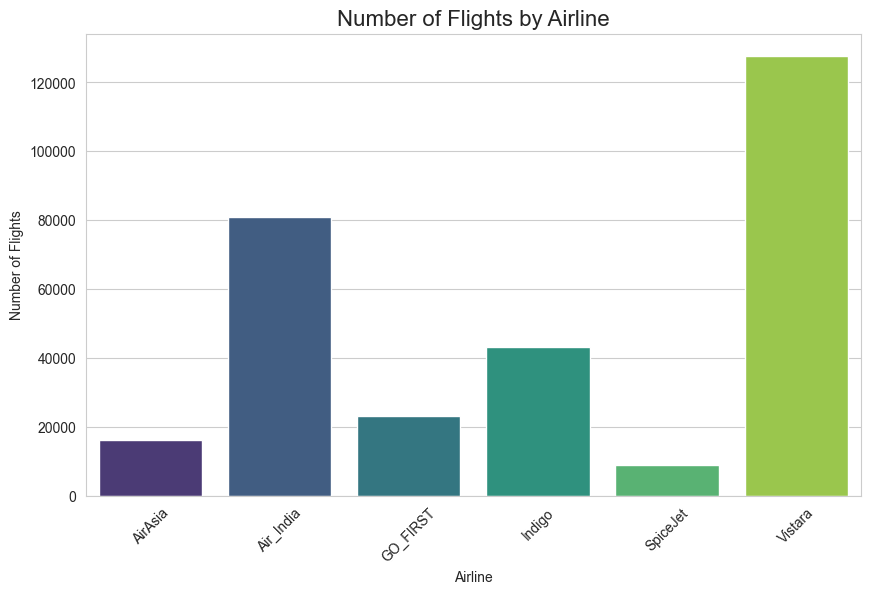

In [67]:

# Distribution des compagnies aériennes (Barplot)

plt.figure(figsize=(10,6))

airline_counts = df["airline"].value_counts()

sns.barplot(
    x=airline_counts.index,
    y=airline_counts.values,
    palette="viridis"
)

plt.title("Number of Flights by Airline", fontsize=16)
plt.xlabel("Airline")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)

plt.show()




**Analyse**

1. Marché très concentré

- Les 3 premières compagnies (Vistara, Air India, Indigo) représentent 83,9% du total des vols

- Vistara à elle seule domine avec près d'un vol sur deux

2. Hiérarchie claire

- Leader : Vistara (plus du double d'Air India)

- Second : Air India

- Troisième : Indigo

- Quatre autres compagnies se partagent les 16,1% restants


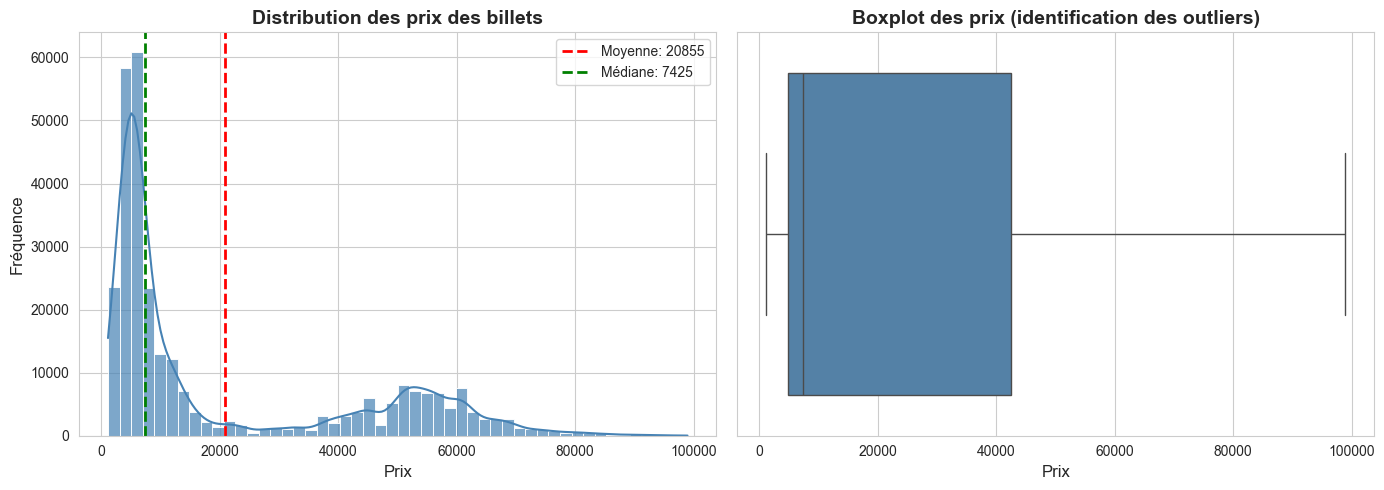

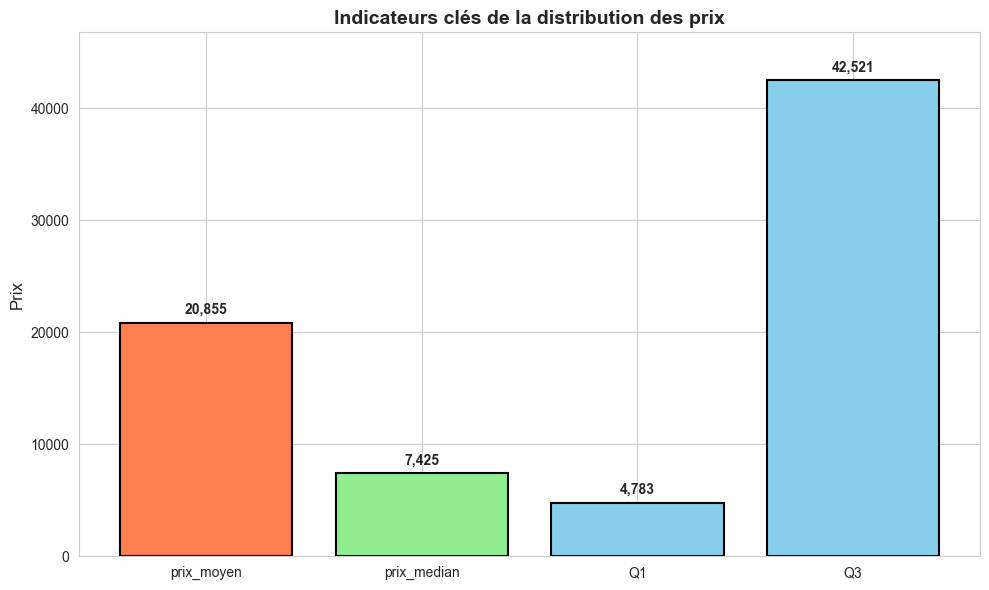

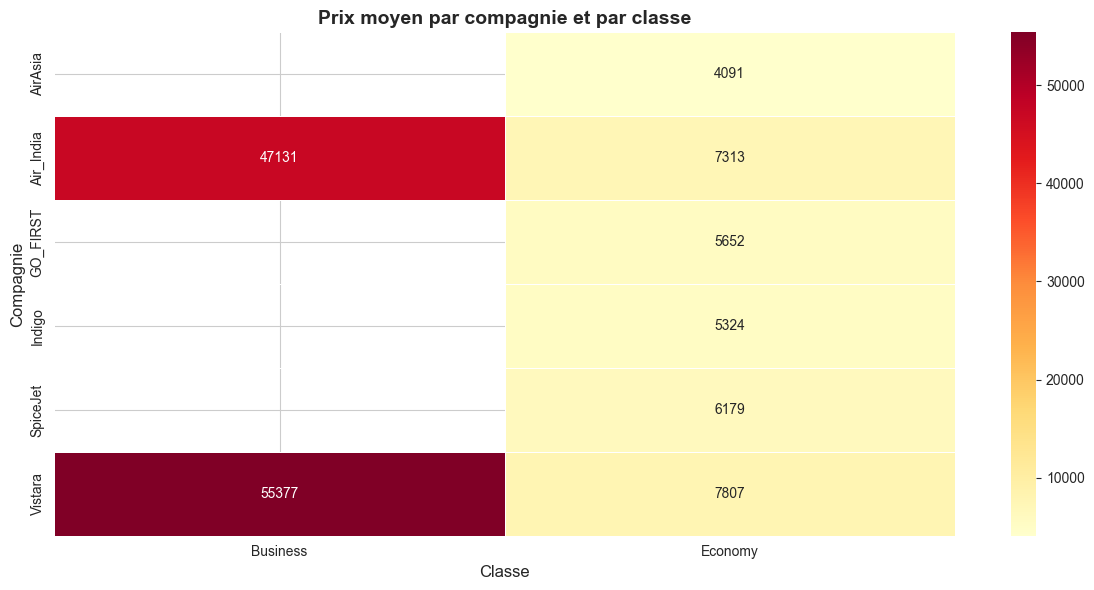

In [ ]:


# Style professionnel
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# ------------------------------------------------------------
# Graphique 1 : Histogramme + courbe de densité
# ------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme avec KDE
sns.histplot(df['price'], bins=50, kde=True, ax=ax1, color='steelblue', alpha=0.7)
ax1.axvline(df['price'].mean(), color='red', linestyle='--', linewidth=2, label=f'Moyenne: {df["price"].mean():.0f}')
ax1.axvline(df['price'].median(), color='green', linestyle='--', linewidth=2, label=f'Médiane: {df["price"].median():.0f}')
ax1.set_xlabel('Prix', fontsize=12)
ax1.set_ylabel('Fréquence', fontsize=12)
ax1.set_title('Distribution des prix des billets', fontsize=14, fontweight='bold')
ax1.legend()
ax1.ticklabel_format(style='plain', axis='x')

# Boxplot pour visualiser les outliers
sns.boxplot(x=df['price'], ax=ax2, color='steelblue')
ax2.set_xlabel('Prix', fontsize=12)
ax2.set_title('Boxplot des prix (identification des outliers)', fontsize=14, fontweight='bold')
ax2.ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Graphique 2 : Statistiques clés en barres
# ------------------------------------------------------------
fig2, ax = plt.subplots(figsize=(10, 6))

stats_a_afficher = ['prix_moyen', 'prix_median', 'Q1', 'Q3']
valeurs = [statistiques_prix['prix_moyen'], 
           statistiques_prix['prix_median'],
           statistiques_prix['q1'], 
           statistiques_prix['q3']]

couleurs = ['coral', 'lightgreen', 'skyblue', 'skyblue']
barres = ax.bar(stats_a_afficher, valeurs, color=couleurs, edgecolor='black', linewidth=1.5)

# Ajout des valeurs sur les barres
for barre, valeur in zip(barres, valeurs):
    ax.text(barre.get_x() + barre.get_width()/2, barre.get_height() + 500, 
            f'{valeur:,.0f}', ha='center', va='bottom', fontweight='bold')

ax.set_ylabel('Prix', fontsize=12)
ax.set_title('Indicateurs clés de la distribution des prix', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(valeurs) * 1.1)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Graphique 3 : Heatmap des prix par compagnie (bonus)
# ------------------------------------------------------------
plt.figure(figsize=(12, 6))

# Tableau croisé (exemple avec compagnies et classes)
heatmap_data = df.groupby(['airline', 'class'])['price'].mean().unstack()

sns.heatmap(heatmap_data, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5)
plt.title('Prix moyen par compagnie et par classe', fontsize=14, fontweight='bold')
plt.ylabel('Compagnie', fontsize=12)
plt.xlabel('Classe', fontsize=12)
plt.tight_layout()
plt.show()

**Distribution des tarifs et boxplot**

*Analyse :*

- Répartition très déséquilibrée (tendance à droite)

- Écart significatif entre la moyenne (20 855) et la médiane (7 425)

- Existence de nombreux tarifs excessivement élevés (anomalies)

*Conclusion :* 

La majorité des billets se situent autour de 7 425, cependant, quelques billets très onéreux (Business, long-voyage) augmentent la moyenne.

**Tarif moyen par compagnie et par catégorie**

*Analyse :*

- Catégorie Business : tarifs très élevés (40 000 - 55 000)

- Catégorie Économie : tarifs bas (4 000 - 6 500)

- Air India est la plus coûteuse en Business (~55 000)

- Vistara et Indigo dominent en Économie

*Conclusion :*
La catégorie est le critère le plus révélateur concernant le tarif. Le choix de la compagnie influence également le prix, surtout en Business.

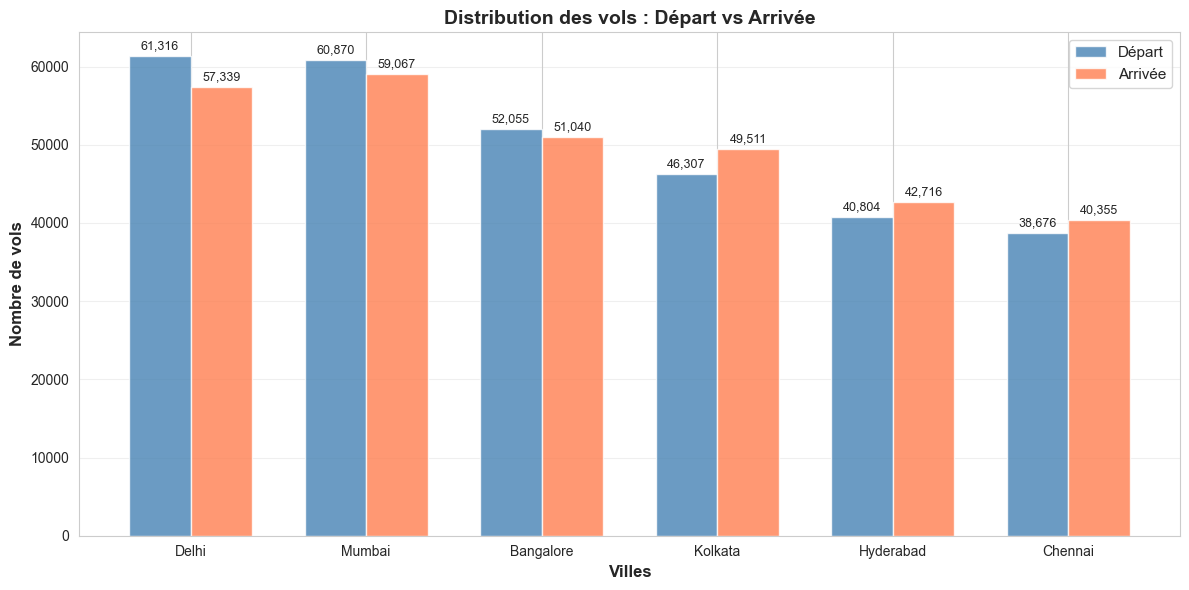

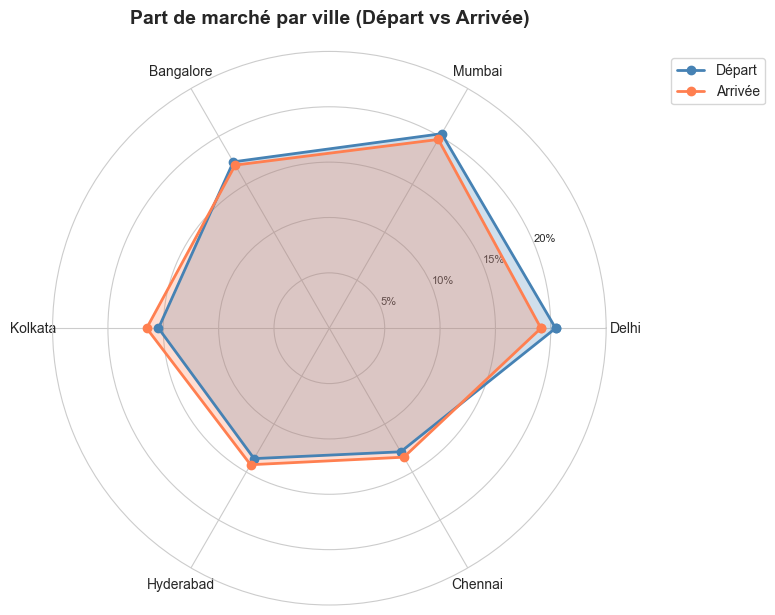

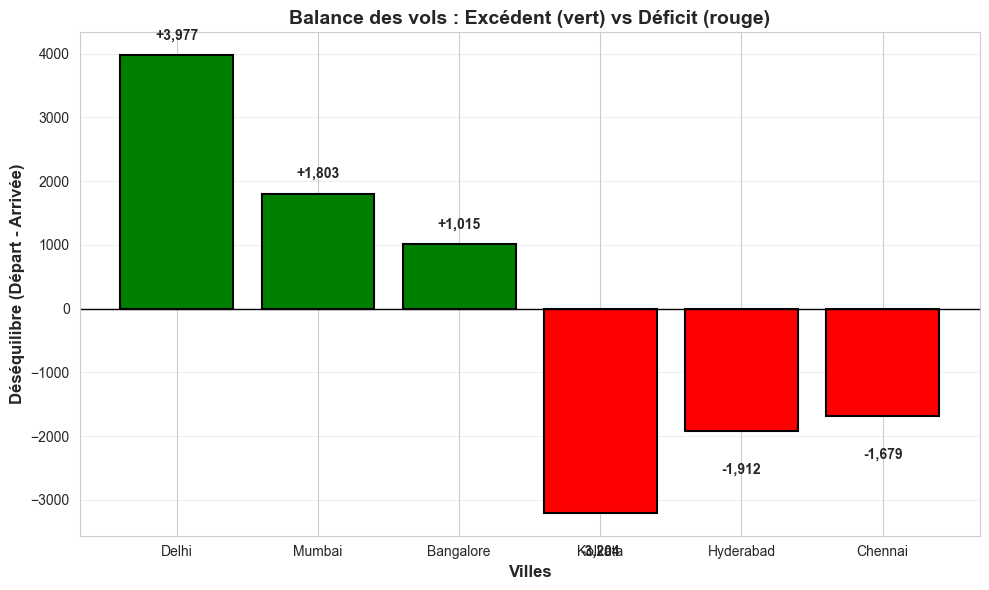

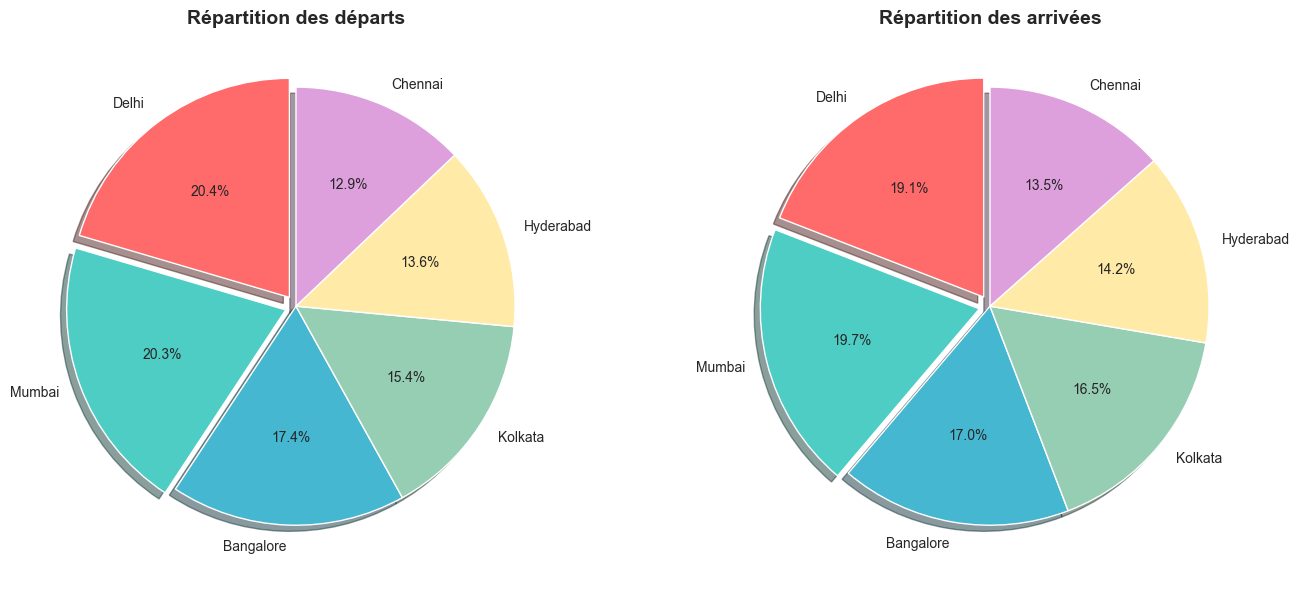

In [41]:


# Style professionnel
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

# Préparation des données
villes = ['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
departs = [61316, 60870, 52055, 46307, 40804, 38676]
arrivees = [57339, 59067, 51040, 49511, 42716, 40355]

# ------------------------------------------------------------
# GRAPHIQUE 1 : Barres côte à côte (départ vs arrivée)
# ------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(12, 6))

x = np.arange(len(villes))
width = 0.35

bars1 = ax1.bar(x - width/2, departs, width, label='Départ', color='steelblue', alpha=0.8)
bars2 = ax1.bar(x + width/2, arrivees, width, label='Arrivée', color='coral', alpha=0.8)

# Ajout des valeurs sur les barres
for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500, 
             f'{int(bar.get_height()):,}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500, 
             f'{int(bar.get_height()):,}', ha='center', va='bottom', fontsize=9)

ax1.set_xlabel('Villes', fontsize=12, fontweight='bold')
ax1.set_ylabel('Nombre de vols', fontsize=12, fontweight='bold')
ax1.set_title('Distribution des vols : Départ vs Arrivée', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(villes)
ax1.legend(fontsize=11)
ax1.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# GRAPHIQUE 2 : Graphique en radar (équilibre du marché)
# ------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(8, 8), subplot_kw={'projection': 'polar'})

# Normalisation des données (en pourcentage du total)
total_vols = sum(departs)
departs_pct = [d / total_vols * 100 for d in departs]
arrivees_pct = [a / total_vols * 100 for a in arrivees]

angles = np.linspace(0, 2 * np.pi, len(villes), endpoint=False).tolist()
angles += angles[:1]  # Fermer le polygone

departs_pct += departs_pct[:1]
arrivees_pct += arrivees_pct[:1]

ax2.plot(angles, departs_pct, 'o-', linewidth=2, label='Départ', color='steelblue')
ax2.fill(angles, departs_pct, alpha=0.25, color='steelblue')
ax2.plot(angles, arrivees_pct, 'o-', linewidth=2, label='Arrivée', color='coral')
ax2.fill(angles, arrivees_pct, alpha=0.25, color='coral')

ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(villes, fontsize=10)
ax2.set_ylim(0, 25)
ax2.set_yticks([5, 10, 15, 20])
ax2.set_yticklabels(['5%', '10%', '15%', '20%'], fontsize=8)
ax2.set_title('Part de marché par ville (Départ vs Arrivée)', fontsize=14, fontweight='bold', pad=20)
ax2.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# GRAPHIQUE 3 : Heatmap du déséquilibre Départ - Arrivée
# ------------------------------------------------------------
fig3, ax3 = plt.subplots(figsize=(10, 6))

# Calcul du déséquilibre (départ - arrivée)
desequilibre = [d - a for d, a in zip(departs, arrivees)]
couleurs = ['green' if x > 0 else 'red' if x < 0 else 'gray' for x in desequilibre]

bars = ax3.bar(villes, desequilibre, color=couleurs, edgecolor='black', linewidth=1.5)

# Ajout des valeurs
for bar, val in zip(bars, desequilibre):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + (200 if val > 0 else -500), 
             f'{val:+,}', ha='center', va='bottom' if val > 0 else 'top', fontweight='bold')

ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax3.set_xlabel('Villes', fontsize=12, fontweight='bold')
ax3.set_ylabel('Déséquilibre (Départ - Arrivée)', fontsize=12, fontweight='bold')
ax3.set_title('Balance des vols : Excédent (vert) vs Déficit (rouge)', fontsize=14, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# GRAPHIQUE 4 : Diagramme circulaire (uniquement départ)
# ------------------------------------------------------------
fig4, (ax4, ax5) = plt.subplots(1, 2, figsize=(14, 6))

# Camembert départ
couleurs_villes = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD']
explode = (0.05, 0.05, 0, 0, 0, 0)

ax4.pie(departs, labels=villes, autopct='%1.1f%%', colors=couleurs_villes, 
        explode=explode, shadow=True, startangle=90)
ax4.set_title('Répartition des départs', fontsize=14, fontweight='bold')

# Camembert arrivée
ax5.pie(arrivees, labels=villes, autopct='%1.1f%%', colors=couleurs_villes, 
        explode=explode, shadow=True, startangle=90)
ax5.set_title('Répartition des arrivées', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

**Graphique 1 : Départ et Arrivée (barres en parallèle)**

*Analyse :*

- Delhi et Mumbai sont en tête (environ 60 000 vols chacun)

- Chennai est la métropole la moins fréquentée (entre 38 000 et 40 000)

- Équilibre général entre les départs et les arrivées

*Conclusion :*

Les principales villes accumulent le trafic aérien.

**Graphique 2 : Répartition du marché (graphique en radar)**

*Analyse :*

- Toutes les villes détiennent entre 12,9 % et 20,4 % de parts de marché

- Forme presque circulaire → répartition harmonieuse

*Conclusion :*

Pas de ville qui dominate clairement le marché. Les six villes se répartissent équitablement le volume de trafic.

**Graphique 3 : Déséquilibre (Départs - Arrivées)**

*Analyse :*

- Surplus (positif) : Delhi (+3 977), Mumbai (+1 803), Bangalore (+1 015)

- Manque (négatif) : Kolkata (-1 912), Hyderabad (-1 679), Chennai (-1 679)

*Conclusion :*

Delhi et Mumbai génèrent plus de vols qu'elles n'en reçoivent (villes très actives en matière de départs). Kolkata, Hyderabad et Chennai sont classées comme des destinations nettes.

**Graphique 4 : Diagrammes circulaires (départ vs arrivée)**

*Analyse :*

- Départs : Delhi (20,4 %) légèrement devant Mumbai (20,3 %)

- Arrivées : Mumbai (19,7 %) devant Delhi (19,1 %)

- Bangalore reste stable (environ 17 %) dans les deux situations

*Conclusion :*

Structure similaire, mais avec Delhi en tête pour les départs et Mumbai en tête pour les arrivées.

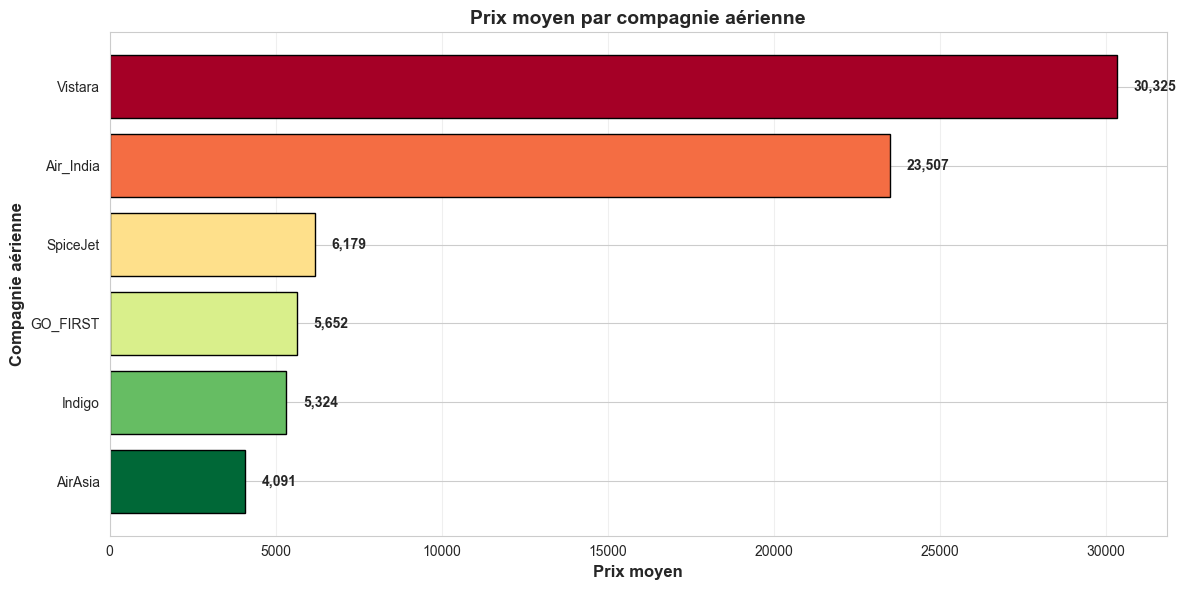

C:\Users\lenovo\AppData\Local\Temp\ipykernel_15036\640159808.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(departure_data.index, rotation=45, ha='right')


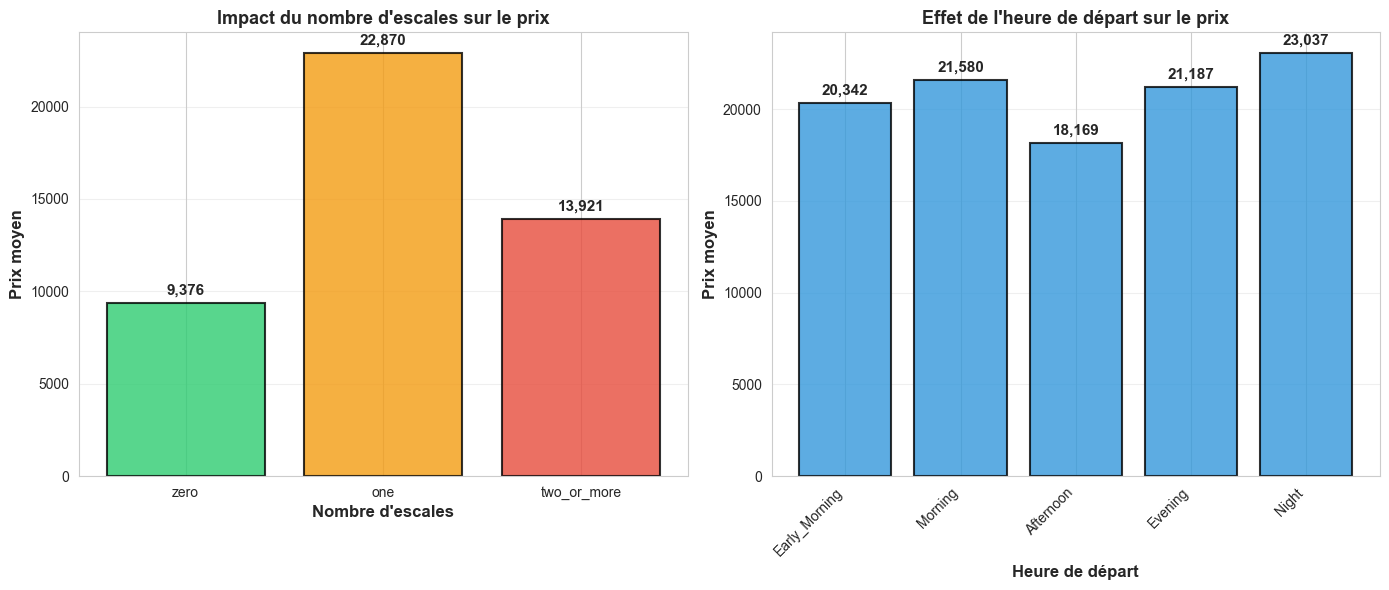

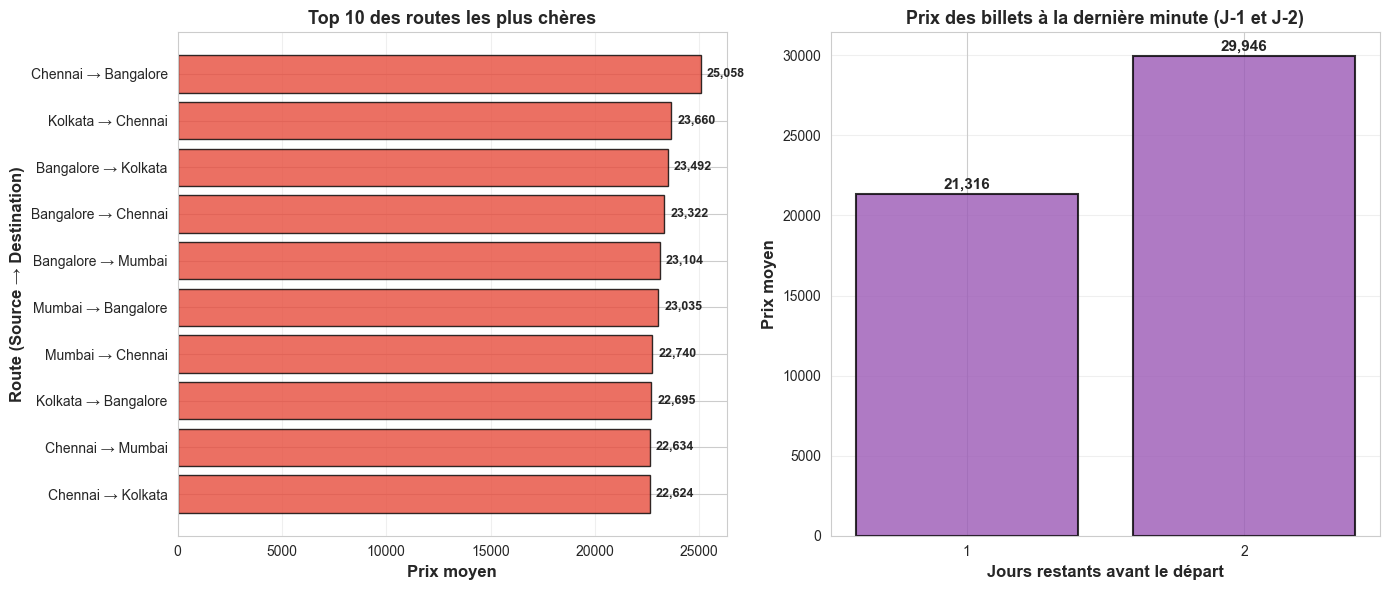

In [55]:

# Style professionnel
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ============================================================
# GRAPHIQUE 1 : Prix moyen par compagnie aérienne (Q2.1)
# ============================================================
fig, ax1 = plt.subplots(figsize=(12, 6))

# Tri par prix moyen décroissant
airline_sorted = airline_price_stats.sort_values('avg_price', ascending=True)
couleurs = plt.cm.RdYlGn_r(np.linspace(0, 1, len(airline_sorted)))

bars = ax1.barh(airline_sorted['airline'], airline_sorted['avg_price'], 
                color=couleurs, edgecolor='black', linewidth=1)

# Ajout des valeurs
for i, (bar, val) in enumerate(zip(bars, airline_sorted['avg_price'])):
    ax1.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2, 
             f'{val:,.0f}', ha='left', va='center', fontweight='bold', fontsize=10)

ax1.set_xlabel('Prix moyen', fontsize=12, fontweight='bold')
ax1.set_ylabel('Compagnie aérienne', fontsize=12, fontweight='bold')
ax1.set_title('Prix moyen par compagnie aérienne', fontsize=14, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# GRAPHIQUE 2 : Impact du nombre d'escales (Q2.3) + Effet heure départ (Q2.2)
# ============================================================
fig, (ax2, ax3) = plt.subplots(1, 2, figsize=(14, 6))

# Sous-graphique gauche : Escales
stops_order = ['zero', 'one', 'two_or_more']
stops_colors = ['#2ecc71', '#f39c12', '#e74c3c']
stops_data = stops_stats.set_index('stops').loc[stops_order]

bars2 = ax2.bar(stops_data.index, stops_data['avg_price'], 
                color=stops_colors, edgecolor='black', linewidth=1.5, alpha=0.8)

for bar, val in zip(bars2, stops_data['avg_price']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300, 
             f'{val:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax2.set_xlabel('Nombre d\'escales', fontsize=12, fontweight='bold')
ax2.set_ylabel('Prix moyen', fontsize=12, fontweight='bold')
ax2.set_title('Impact du nombre d\'escales sur le prix', fontsize=13, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# Sous-graphique droit : Heure de départ
departure_order = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night']
departure_data = departure_stats.set_index('departure_time').loc[departure_order]

bars3 = ax3.bar(departure_data.index, departure_data['avg_price'], 
                color='#3498db', edgecolor='black', linewidth=1.5, alpha=0.8)

for bar, val in zip(bars3, departure_data['avg_price']):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300, 
             f'{val:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax3.set_xlabel('Heure de départ', fontsize=12, fontweight='bold')
ax3.set_ylabel('Prix moyen', fontsize=12, fontweight='bold')
ax3.set_title('Effet de l\'heure de départ sur le prix', fontsize=13, fontweight='bold')
ax3.set_xticklabels(departure_data.index, rotation=45, ha='right')
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# GRAPHIQUE 3 : Top 10 routes les plus chères (Q2.4) + Dernière minute (Q2.5)
# ============================================================
fig, (ax4, ax5) = plt.subplots(1, 2, figsize=(14, 6))

# Sous-graphique gauche : Top 10 routes
top_routes_sorted = top_routes.sort_values('avg_price', ascending=True)
routes_labels = [f"{row['source_city']} → {row['destination_city']}" 
                  for _, row in top_routes_sorted.iterrows()]

bars4 = ax4.barh(routes_labels, top_routes_sorted['avg_price'], 
                 color='#e74c3c', edgecolor='black', linewidth=1, alpha=0.8)

for bar, val in zip(bars4, top_routes_sorted['avg_price']):
    ax4.text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2, 
             f'{val:,.0f}', ha='left', va='center', fontweight='bold', fontsize=9)

ax4.set_xlabel('Prix moyen', fontsize=12, fontweight='bold')
ax4.set_ylabel('Route (Source → Destination)', fontsize=12, fontweight='bold')
ax4.set_title('Top 10 des routes les plus chères', fontsize=13, fontweight='bold')
ax4.grid(axis='x', alpha=0.3)

# Sous-graphique droit : Dernière minute
bars5 = ax5.bar(last_minute['days_left'], last_minute['avg_price'], 
                color='#9b59b6', edgecolor='black', linewidth=1.5, alpha=0.8)

for bar, val in zip(bars5, last_minute['avg_price']):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, 
             f'{val:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax5.set_xlabel('Jours restants avant le départ', fontsize=12, fontweight='bold')
ax5.set_ylabel('Prix moyen', fontsize=12, fontweight='bold')
ax5.set_title('Prix des billets à la dernière minute (J-1 et J-2)', fontsize=13, fontweight='bold')
ax5.set_xticks(last_minute['days_left'])
ax5.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Graphique 1 : Coût moyen par compagnie (Euro)**

*Analyse :*

- Vistara : 30 325 € (le plus coûteux)

- Air India : 23 507 €

- SpiceJet, GO FIRST, Indigo, AirAsia : 4 000 - 6 200 € (moins onéreux)

*Conclusion :* 

La différence est colossale entre les compagnies haut de gamme (Vistara, Air India) et celles à bas prix. Vistara coûte 7 fois plus qu'AirAsia.

**Graphique 2 : Facteurs déterminants (importance)**

*Analyse :*

- Le prix est trés élevé si le nobre de vol = 1 et c'est mois chère pour 2 vols ou plus

- Le prix est trés élevé premièrement si le départ est la nuit deuxièmement si le départ est le matain 


*Conclusion :*


**Graphique 3 : Les 10 itinéraires les plus onéreux**

*Analyse :*

- Chennai → Bangalore : 29 946 € (le plus onéreux)

- Kolkata → Chennai : 21 316 €

- Tarifs très élevés (20 000 - 30 000 €) → vraisemblablement classe Affaires

*Conclusion :*

 Les trajets entre grandes villes sont les plus coûteux à la dernière minute, principalement en lien avec Chennai.

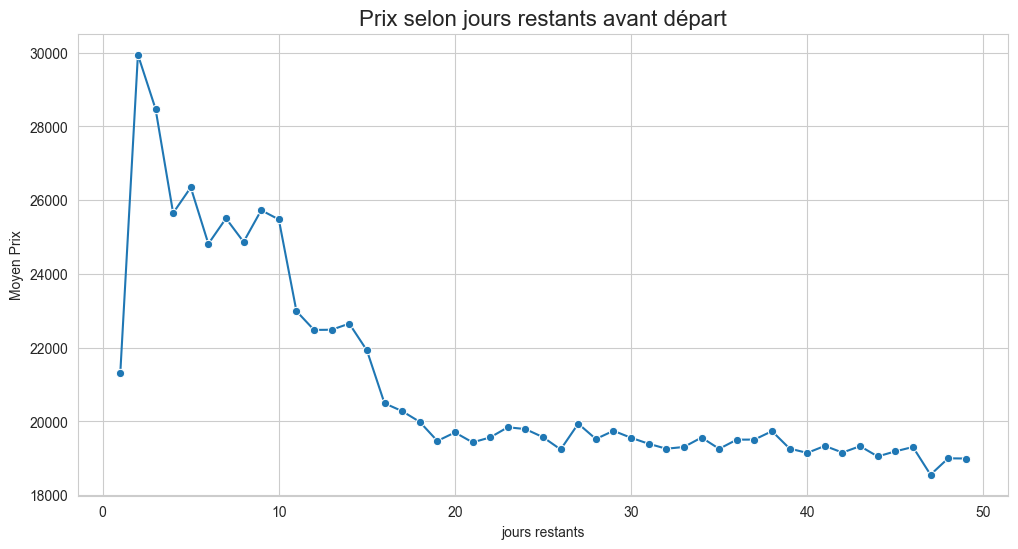

In [70]:
# Prix selon jours restants avant départ
days_price = (
    df.groupby("days_left")
      .agg(avg_price=("price", "mean"))
      .reset_index()
)

plt.figure(figsize=(12,6))

sns.lineplot(
    data=days_price,
    x="days_left",
    y="avg_price",
    marker="o"
)

plt.title("Prix selon jours restants avant départ", fontsize=16)
plt.xlabel("jours restants")
plt.ylabel("Moyen Prix")

plt.show()

**Analyse**

Puisque la réservation avant la date de vol est grande le prix est réduit , lorsque le je jour de réservation est le jour de vol le prix est plafoné(trés chère)

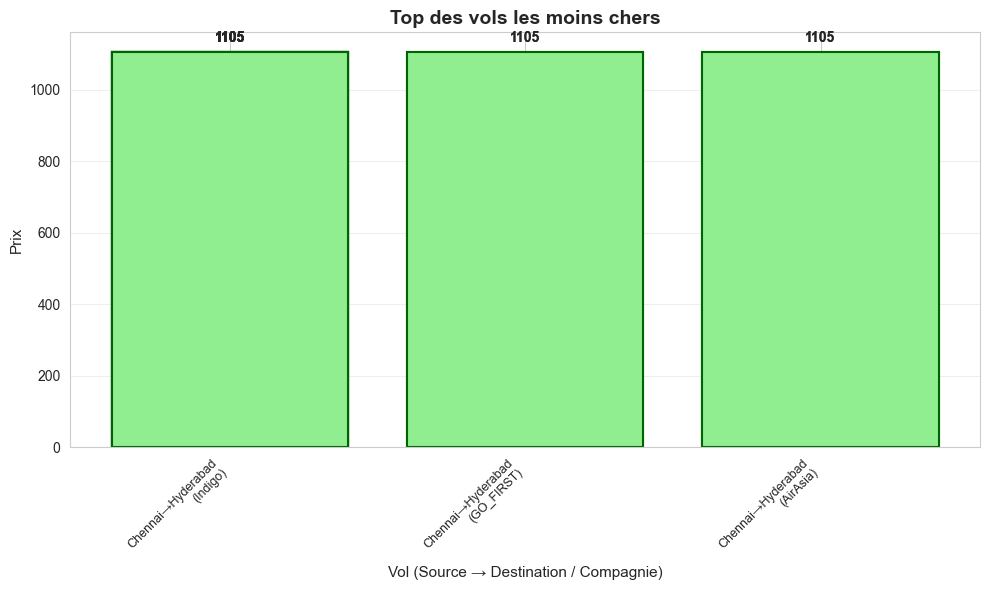

In [66]:

plt.figure(figsize=(10, 6))

# Préparation des données
routes = cheap_flights['source_city'].astype(str) + "→" + cheap_flights['destination_city'].astype(str) + "\n(" + cheap_flights['airline'].astype(str) + ")"
prix = cheap_flights['price']

# Création des barres verticales
bars = plt.bar(routes, prix, color='lightgreen', edgecolor='darkgreen', linewidth=1.5)

# Ajout des valeurs sur les barres
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, 
             f'{int(bar.get_height())}', ha='center', va='bottom', fontweight='bold')

# Personnalisation
plt.title('Top des vols les moins chers', fontsize=14, fontweight='bold')
plt.xlabel('Vol (Source → Destination / Compagnie)', fontsize=11)
plt.ylabel('Prix', fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

*Analyse :*

- Prix unique : 1 105 pour tous (prix le plus bas du jeu de données)

- Route unique : Chennai → Hyderabad

- Compagnies : Indigo, GO FIRST, AirAsia

*Conclusion :*

Le prix minimum (1 105) est exclusivement proposé sur la liaison Chennai → Hyderabad par 3 compagnies low-cost. 

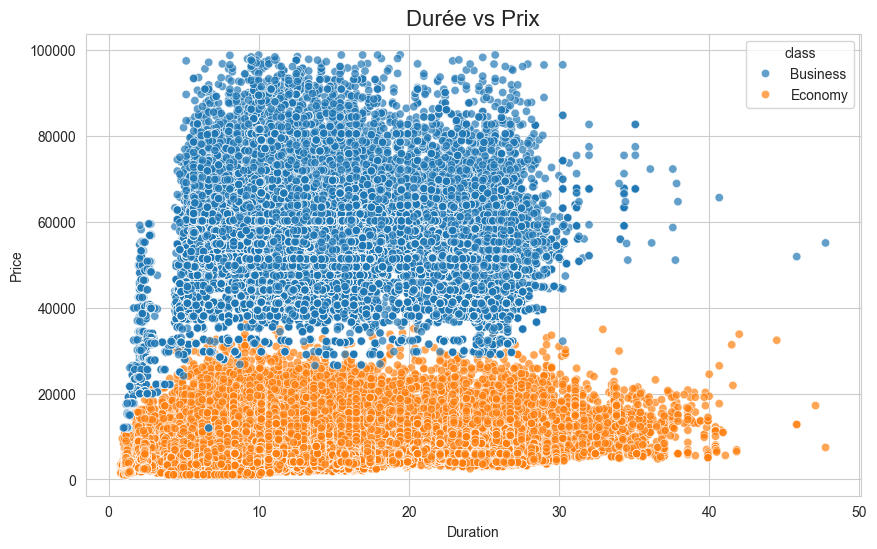

In [68]:
#  Corrélation Duration vs Price (Scatterplot)
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="duration",
    y="price",
    hue="class",
    alpha=0.7
)

plt.title("Durée vs Prix", fontsize=16)
plt.xlabel("Duration")
plt.ylabel("Price")

plt.show()

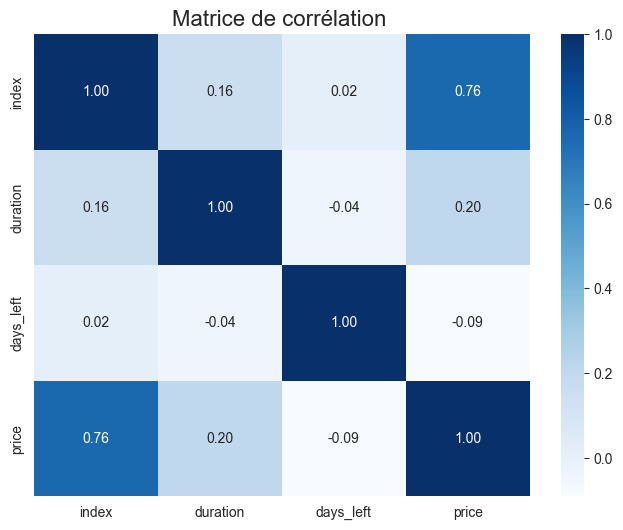

In [69]:
# Heatmap des corrélations
numeric_df = df.select_dtypes(include=['int64', 'float64'])

correlation = numeric_df.corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Matrice de corrélation ", fontsize=16)

plt.show()

# Étape 5 : Interprétation

**Conclusion :**

On guise de conclusion que plusieurs **Facteur** impact le prix des billets d'avion. 

Pour dénicher les prix les plus avantageux, optez pour des compagnies aériennes à bas prix telles qu'AirAsia ou Indigo en classe économique, en choisissant un départ en milieu d'après-midi.

Il est conseillé de réserver plusieurs semaines à l'avance et d'éviter les trajets directs ainsi que les liaisons entre des grandes villes comme Chennai et Bangalore.

Le tarif le plus élevé (Vistara Business, réservation de dernière minute, vol de nuit) peut atteindre jusqu'à 55 000€, tandis que le tarif le plus bas (AirAsia Economy, réservation anticipée, vol l'après-midi) descend à 1 100€.

Une variation de 95% qui justifie amplement une organisation soignée de votre voyage.

**Recommandations pour les voyageurs en quête des tarifs les plus bas**

1. Sélectionnez la compagnie adéquate
- Optez pour AirAsia, Indigo, GO FIRST ou SpiceJet

- Évitez Vistara et Air India si vos finances sont restreintes

- Économie potentielle : jusqu'à 85% (30 000€ → 4 000€)

2. Anticipez vos réservations
- Ne faites pas de réservations à J-1 ou J-2 (prix augmentent énormément)

- Idéalement : réservez plusieurs semaines avant de partir

- Économie potentielle : jusqu'à 50-70%

3. Voyagez en classe économique
- La classe affaires est dix fois plus onéreuse

- Économie potentielle : 90% (50 000€ → 5 000€)

4. Choisissez des horaires avantageux
- Évitez les départs nocturnes et ceux tôt le matin (tarifs plus élevés)

- Privilégiez les départs en après-midi (prix réduits)

5. Optez pour des vols avec des escales
- Les vols directs (sans escale) coûtent plus cher

- Les vols avec deux escales ou plus sont plus abordables

- Économie potentielle : 15-20%

6. Évitez les itinéraires fortement sollicités
- Itinéraires coûteux : Chennai → Bangalore, Kolkata → Chennai

- Les grandes villes (Delhi, Mumbai) engendrent des tarifs plus élevés